# 02b — A3 con presupuesto extendido (CISUTAC Holes)

Este notebook ejecuta **únicamente** la variante ganadora de validación del notebook 02:

- YOLO11n preentrenado en COCO.
- Tiles de 640 × 640.
- Solapamiento del 20 %.
- Un tile sano por cada tile con defecto (`NEG_POR_POS = 1`).
- Presupuesto extendido: hasta 100 épocas, con paciencia 30.

La A3 original fue limitada a 26 épocas para igualar imágenes vistas con A0 y obtuvo **mAP@0.5 = 0,131** en validación. Como su mejor época fue la última, esta corrida comprueba si A3 seguía mejorando.

> **Este notebook no evalúa test.** Sólo usa `valid`. El test debe abrirse una única vez después de comparar esta corrida con la A3 original y congelar la variante definitiva.

> **Versión ejecutada en Kaggle** (GPU T4 x2, versión 1, ~23 min en total). Es `notebooks/02b_a3_presupuesto_extendido_holes.ipynb` con un único cambio, en la celda de preparación: baja **sólo CISUTAC Holes** (no Spots, que este notebook no usa), prepara sólo Holes con una copia de `scripts/prepare_cisutac_yolo.py` restringida a Holes (el script del repo no se modificó) y guarda los datos en `/tmp` para que no ocupen el Output. El split resultante es el mismo de la A3 original (300 / 43 / 64 fotos; 162 tiles y 123 cajas en valid).
>
> **Resultado en valid:** las 100 épocas corrieron completas (sin *early stopping*). mAP@0.5 = **0,107** (A3 original: 0,131), AP_small = 0,031 (0,077), recall = 0,197 (0,11–0,29) contra 0,225 (0,14–0,32). Los intervalos se superponen (la diferencia es de 2 agujeros sobre 71): **más épocas no mejoran A3**, así que la variante para test sigue siendo la A3 original (tiles 640, neg 1, 26 épocas). Test no se evaluó.

## 0. Preparación para Kaggle

Activar una GPU e Internet. La celda instala dependencias, clona el repositorio y descarga CISUTAC Holes si todavía no está disponible.

In [1]:
%pip install -q ultralytics==8.4.215 sahi==0.14.0 pycocotools==2.0.11 huggingface_hub
import os, subprocess, sys
from pathlib import Path
ROOT = Path('/kaggle/working/tp_final_vision')
DATA_ROOT = Path('/tmp/rewear_data')  # fuera de /kaggle/working: los datos no ocupan lugar en el Output
if not ROOT.exists(): subprocess.run(['git', 'clone', '-q', 'https://github.com/victoriapersico/tp_final_vision.git', str(ROOT)], check=True)
os.environ['REWEAR_DATA_DIR'] = str(DATA_ROOT)
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / 'src'))
# Solo CISUTAC Holes (~231 MB): Spots no se usa en este notebook
subprocess.run([sys.executable, 'scripts/download_datasets.py', 'holes'], check=True)
# prepare_cisutac_yolo.py procesa Holes y Spots juntos: se usa una copia que procesa solo Holes (el repo no cambia)
codigo = (ROOT / 'scripts' / 'prepare_cisutac_yolo.py').read_text(encoding='utf-8')
viejo = '(("Holes", "cisutac_holes"), ("Spots", "cisutac_spots"))'
assert viejo in codigo, 'prepare_cisutac_yolo.py cambio: revisar'
(ROOT / 'scripts' / '_prepare_solo_holes.py').write_text(codigo.replace(viejo, '(("Holes", "cisutac_holes"),)'), encoding='utf-8')
subprocess.run([sys.executable, 'scripts/_prepare_solo_holes.py'], check=True)
print('Repositorio:', ROOT)
print('Datos:', DATA_ROOT / 'cisutac_holes')

Note: you may need to restart the kernel to use updated packages.


Hint: A new version of huggingface_hub (2.4.0) is available! You are using version 1.33.0.
To update, run: hf update
Hint: The `hf-cli` skill is not installed. Run `hf skills add -g` to teach your AI agents how to use the `hf` CLI.
Fetching 1525 files: 100%|██████████| 1525/1525 [04:53<00:00,  5.20it/s]


✓ Downloaded
  path: /tmp/rewear_data/cisutac_holes
holes: intento 1/6
holes: descarga finalizada en /tmp/rewear_data/cisutac_holes
Holes train: 300 imágenes, 589 cajas
Holes valid: 43 imágenes, 71 cajas
Holes test: 64 imágenes, 125 cajas
Holes: escrito en /tmp/rewear_data/derived/cisutac_holes
Repositorio: /kaggle/working/tp_final_vision
Datos: /tmp/rewear_data/cisutac_holes


## 1. Parámetros congelados

El único cambio respecto de la A3 original es el presupuesto de épocas. El nombre nuevo evita sobrescribir la corrida de Pepo.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

import cisutac_baseline as cb

DATASET = 'holes'
MODELO = 'yolo11n.pt'
SEMILLA = 0
TILE = 640
SOLAPAMIENTO = 0.20
NEG_POR_POS = 1.0
MIN_VISIBLE = 0.50
EPOCAS_EXTENDIDAS = 100
PACIENCIA = 30
BATCH = 16
CONF_EVAL = 0.001
NOMBRE_CORRIDA = 'holes_A3_tiles640_neg1_ext100'
SPLIT_EVALUACION = 'valid'

assert SPLIT_EVALUACION == 'valid', 'Este notebook no debe abrir test.'
print('Dispositivo:', cb.pick_device())
print('Resultados:', cb.RESULTS)

Dispositivo: 0
Resultados: /kaggle/working/tp_final_vision/results/cisutac/bloque_a


## 2. Preparación de datos y tiles

Se conserva exactamente el split y la construcción de tiles del notebook 02.

In [3]:
if not (cb.derived_dir(DATASET) / 'data.yaml').exists():
    subprocess.run([sys.executable, str(ROOT / 'scripts' / 'prepare_cisutac_yolo.py')], check=True)

yaml_tiles, stats_tiles = cb.build_tile_dataset(
    DATASET,
    tile=TILE,
    overlap=SOLAPAMIENTO,
    neg_per_pos=NEG_POR_POS,
    seed=SEMILLA,
    min_visible=MIN_VISIBLE,
)

display(pd.DataFrame(stats_tiles).T)
print('Dataset YOLO de tiles:', yaml_tiles)

,imagenes_originales,tiles_posibles,tiles_con_defecto,tiles_sin_defecto_disponibles,tiles_sin_defecto_usados,tiles_descartados_por_fragmentos,tiles_totales,cajas
train,300,9576,585,8878,585,113,1170,874
valid,43,1376,81,1270,81,25,162,123


Dataset YOLO de tiles: /tmp/rewear_data/derived/cisutac_holes_tiles/t640_o20/data_neg1_s0.yaml


## 3. Entrenamiento A3 extendido

A diferencia de la A3 original, esta corrida permite hasta 100 épocas. El *early stopping* puede detenerla antes si validación deja de mejorar durante 30 épocas.

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
New https://pypi.org/project/ultralytics/8.4.216 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/tmp/rewear_data/derived/cisutac_holes_tiles/t640_o20/data_neg1_s0.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=F

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


      2/100      2.73G      2.845      3.785      1.824          3        640: 100% ━━━━━━━━━━━━ 74/74 9.0it/s 8.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 6.2it/s 1.0s
                   all        162        123     0.0269      0.065     0.0202     0.0065

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      3/100      2.74G      3.033       3.65      2.045          1        640: 100% ━━━━━━━━━━━━ 74/74 9.1it/s 8.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 6.7it/s 0.9s
                   all        162        123    0.00132      0.154   0.000406   8.26e-05

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      4/100      2.74G      2.983      3.705      2.087          3        640: 100% ━━━━━━━━━━━━ 74/74 9.2it/s 8.0s
                 Class     Images  Instances      Box(P          R

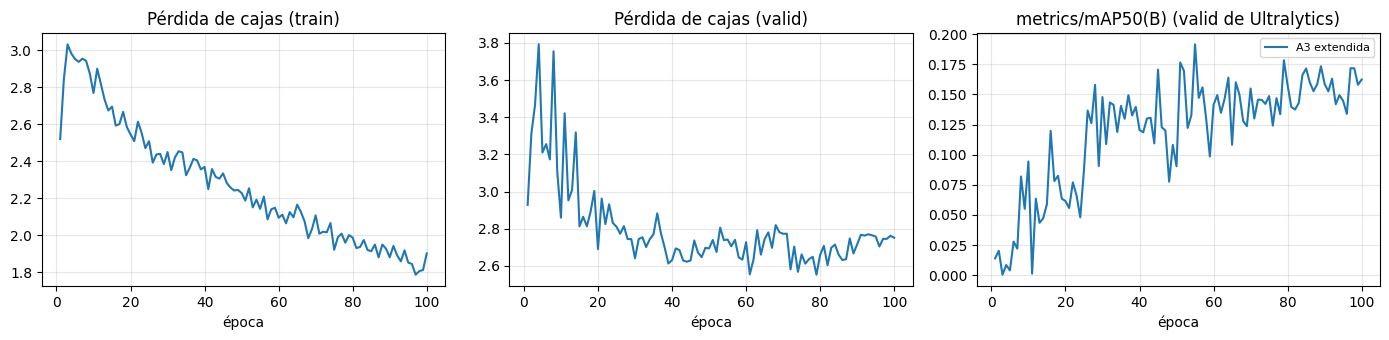

In [4]:
run_ext = cb.train(
    NOMBRE_CORRIDA,
    yaml_tiles,
    imgsz=TILE,
    epochs=EPOCAS_EXTENDIDAS,
    patience=PACIENCIA,
    batch=BATCH,
    seed=SEMILLA,
    model=MODELO,
    retrain=False,
)

cb.plot_curves({'A3 extendida': run_ext});

## 4. Evaluación únicamente en validación

,modo,mAP@0.5,mAP@0.5:0.95,AP_small,AP_medium,AP_large,umbral_confianza,precision,recall,f1,segundos_por_imagen,tiles_por_imagen,recall (IC 95 %)
corrida,,,,,,,,,,,,,
holes_A3_tiles640_neg1_ext100__valid_tiles640_o20,tiles,0.107,0.043,0.031,0.08,0.04,0.38,0.241,0.197,0.217,0.441,32.0,0.197 (0.110–0.294)


,< 8 px,8–16 px,16–32 px,32–64 px,≥ 64 px
holes_A3_tiles640_neg1_ext100__valid_tiles640_o20,0/4,2/15,4/16,4/19,4/17


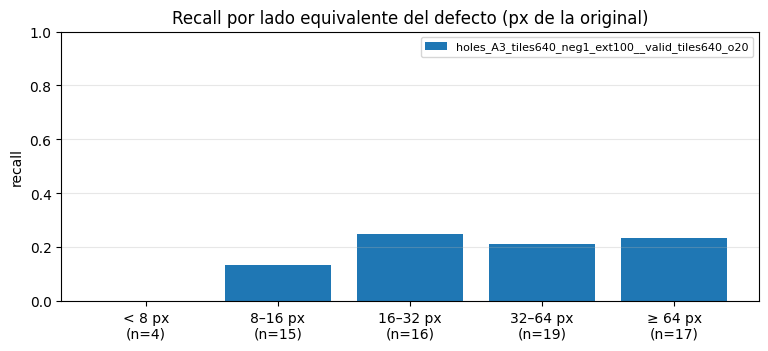

In [5]:
eval_ext = cb.evaluate(
    f'{NOMBRE_CORRIDA}__valid_tiles640_o20',
    DATASET,
    Path(run_ext) / 'weights' / 'best.pt',
    split=SPLIT_EVALUACION,
    mode='tiles',
    tile=TILE,
    overlap=SOLAPAMIENTO,
    also_full=False,
    conf=CONF_EVAL,
    reevaluate=False,
)

display(cb.metrics_table([eval_ext]))
display(cb.size_table([eval_ext]))
cb.plot_recall_by_size([eval_ext]);

## 5. Comparación con la A3 original

La fila original usa los resultados guardados por Pepo. La decisión se toma por mAP@0.5 en `valid`; test continúa cerrado.

In [6]:
comparacion = pd.DataFrame([
    {
        'variante': 'A3 original — presupuesto igualado (26 épocas máx.)',
        'mAP@0.5': 0.131,
        'mAP@0.5:0.95': 0.039,
        'AP_small': 0.077,
        'recall': 0.225,
        'segundos_por_imagen': 0.454,
    },
    {
        'variante': 'A3 extendida — hasta 100 épocas',
        'mAP@0.5': eval_ext['mAP@0.5'],
        'mAP@0.5:0.95': eval_ext['mAP@0.5:0.95'],
        'AP_small': eval_ext['AP_small'],
        'recall': eval_ext['recall'],
        'segundos_por_imagen': eval_ext['segundos_por_imagen'],
    },
]).set_index('variante')
display(comparacion)

if eval_ext['mAP@0.5'] > 0.131:
    print('La A3 extendida supera el mAP@0.5 de validación de la original.')
elif eval_ext['mAP@0.5'] == 0.131:
    print('Empate en mAP@0.5: se prefiere la corrida de menor presupuesto.')
else:
    print('La A3 original conserva el mejor mAP@0.5 de validación.')

,mAP@0.5,mAP@0.5:0.95,AP_small,recall,segundos_por_imagen
variante,,,,,
A3 original — presupuesto igualado (26 épocas máx.),0.131000,0.039000,0.077000,0.225000,0.4540
A3 extendida — hasta 100 épocas,0.107046,0.042727,0.031393,0.197183,0.4409


La A3 original conserva el mejor mAP@0.5 de validación.


## 6. Próximo paso

1. Guardar esta corrida con **Save Version → Save & Run All**.
2. Confirmar que finalice como `Successful`.
3. Comparar el mAP@0.5 de validación con 0,131.
4. Congelar la variante elegida.
5. Recién después preparar la evaluación única en test en otro notebook o versión explícita.

No modificar hiperparámetros usando resultados de test.